In [49]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
def create_polynomial_features(X, degree):
    X = np.asarray(X, dtype = float).reshape(-1)

    features = []
    for d in range(degree + 1):
        feature = X ** d
        features.append(feature)
    return np.column_stack(features)

In [50]:
X = np.array([0, 1, 2, 3, 4, 5])

X_poly = create_polynomial_features(
    X,
    degree=2
)

print(X_poly)
print(X_poly.shape)

[[ 1.  0.  0.]
 [ 1.  1.  1.]
 [ 1.  2.  4.]
 [ 1.  3.  9.]
 [ 1.  4. 16.]
 [ 1.  5. 25.]]
(6, 3)


In [51]:
import numpy as np
from sklearn.preprocessing import PolynomialFeatures

X = np.array([0, 1, 2, 3, 4, 5]).reshape(-1, 1)

poly = PolynomialFeatures(
    degree=2,
    include_bias=True
)

X_poly = poly.fit_transform(X)

print(X_poly)
print("Shape:", X_poly.shape)


[[ 1.  0.  0.]
 [ 1.  1.  1.]
 [ 1.  2.  4.]
 [ 1.  3.  9.]
 [ 1.  4. 16.]
 [ 1.  5. 25.]]
Shape: (6, 3)


In [52]:
df = pd.read_csv('data/Salaries.csv')
df

,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000
5,Region Manager,6,150000
6,Partner,7,200000
7,Senior Partner,8,300000
8,C-level,9,500000
9,CEO,10,1000000


In [53]:
X = df.Level
X

0     1
1     2
2     3
3     4
4     5
5     6
6     7
7     8
8     9
9    10
Name: Level, dtype: int64

In [54]:
y = df.Salary
y

0      45000
1      50000
2      60000
3      80000
4     110000
5     150000
6     200000
7     300000
8     500000
9    1000000
Name: Salary, dtype: int64

Text(0, 0.5, 'Salary')

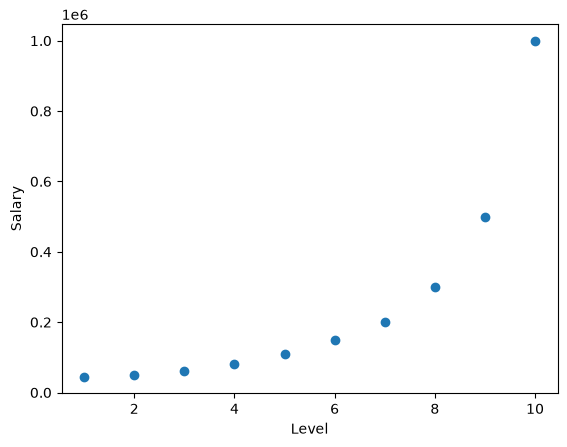

In [55]:
plt.scatter(X, y)
plt.xlabel('Level')
plt.ylabel('Salary')

In [56]:
def r2score(y_pred, y):
    rss = np.sum((y_pred - y) ** 2)
    tss = np.sum((y - y.mean()) ** 2)
    r2 = 1 - (rss / tss)
    return r2

In [57]:
class LinearRegression:
    def __init__(self, X_data, y_target, learning_rate = 0.01, num_epochs = 10000):
        self.X_data = X_data
        self.y_target = y_target
        self.learning_rate = learning_rate
        self.num_epochs = num_epochs
        self.num_samples = self.X_data.shape[0]
        self.theta = np.random.randn(self.X_data.shape[1])
        self.losses = []
    def compute_loss(self, y_pred, y_target):
        loss = (y_pred - y_target) ** 2
        loss = np.mean(loss)
        return loss
    def predict(self, X_data):
        y_pred = X_data.dot(self.theta)
        return y_pred
    def fit(self):
        for epoch in range(self.num_epochs):
            y_pred = self.predict(self.X_data)
            loss = self.compute_loss(y_pred, self.y_target)
            self.losses.append(loss)

            k = 2 * (y_pred - self.y_target)
            gradients = self.X_data.T.dot(k) / self.num_samples

            self.theta = self.theta - self.learning_rate * gradients
            print(f'Epoch: {epoch} - Loss : {loss}')
        return {
            'loss': sum(self.losses) / len(self.losses),
            'weight': self.theta
        }


In [58]:
X_linear = X.values.reshape(-1, 1)
print(X_linear)
X_linear = np.hstack((np.ones((X_linear.shape[0], 1)), X_linear))
print(X_linear)

[[ 1]
 [ 2]
 [ 3]
 [ 4]
 [ 5]
 [ 6]
 [ 7]
 [ 8]
 [ 9]
 [10]]
[[ 1.  1.]
 [ 1.  2.]
 [ 1.  3.]
 [ 1.  4.]
 [ 1.  5.]
 [ 1.  6.]
 [ 1.  7.]
 [ 1.  8.]
 [ 1.  9.]
 [ 1. 10.]]


In [59]:
linear_model = LinearRegression(X_linear, y, learning_rate = 0.02, num_epochs = 100)
linear_model.fit()

Epoch: 0 - Loss : 142909322239.67178
Epoch: 1 - Loss : 70451022146.0181
Epoch: 2 - Loss : 46680125425.604904
Epoch: 3 - Loss : 38818366516.54305
Epoch: 4 - Loss : 36156153872.88061
Epoch: 5 - Loss : 35194341587.14797
Epoch: 6 - Loss : 34789635890.09756
Epoch: 7 - Loss : 34568465396.33549
Epoch: 8 - Loss : 34408748708.28236
Epoch: 9 - Loss : 34270573575.180656
Epoch: 10 - Loss : 34140875091.786755
Epoch: 11 - Loss : 34015360531.313313
Epoch: 12 - Loss : 33892603682.392815
Epoch: 13 - Loss : 33772115299.157288
Epoch: 14 - Loss : 33653712657.378277
Epoch: 15 - Loss : 33537313564.540016
Epoch: 16 - Loss : 33422869050.841713
Epoch: 17 - Loss : 33310341371.19613
Epoch: 18 - Loss : 33199696811.68685
Epoch: 19 - Loss : 33090903333.15464
Epoch: 20 - Loss : 32983929795.309193
Epoch: 21 - Loss : 32878745697.342327
Epoch: 22 - Loss : 32775321087.394672
Epoch: 23 - Loss : 32673626527.28846
Epoch: 24 - Loss : 32573633075.41224
Epoch: 25 - Loss : 32475312275.629913
Epoch: 26 - Loss : 32378636148.2501

{'loss': np.float64(32583646794.83198),
 'weight': array([-108098.24622277,   68348.29191287])}

In [60]:
y_pred = linear_model.predict(X_linear)

In [61]:
print(r2score(y_pred, y))

0.6488225358822217


In [62]:
linear_model.theta

array([-108098.24622277,   68348.29191287])

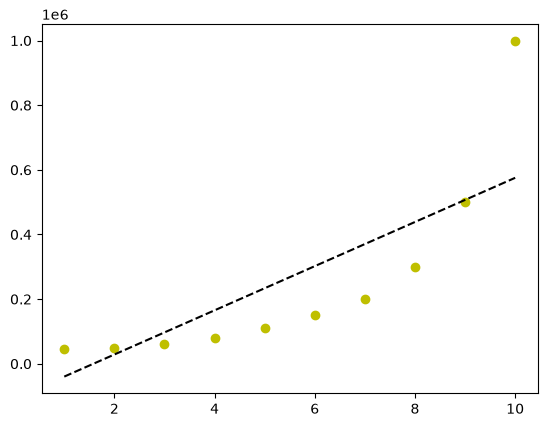

In [63]:
plt.plot(X, y, 'yo', X, linear_model.theta[1] * X + linear_model.theta[0], '--k')
plt.show()

In [64]:
X_poly = create_polynomial_features(X, degree = 2)
X_poly

array([[  1.,   1.,   1.],
       [  1.,   2.,   4.],
       [  1.,   3.,   9.],
       [  1.,   4.,  16.],
       [  1.,   5.,  25.],
       [  1.,   6.,  36.],
       [  1.,   7.,  49.],
       [  1.,   8.,  64.],
       [  1.,   9.,  81.],
       [  1.,  10., 100.]])

In [65]:
poly_model = LinearRegression(X_poly, y, learning_rate = 0.00001, num_epochs = 100)
poly_model.fit()

Epoch: 0 - Loss : 142897713651.62448
Epoch: 1 - Loss : 130147701943.62968
Epoch: 2 - Loss : 118674678504.19736
Epoch: 3 - Loss : 108350740600.07108
Epoch: 4 - Loss : 99060796195.03415
Epoch: 5 - Loss : 90701280834.573
Epoch: 6 - Loss : 83179003046.96387
Epoch: 7 - Loss : 76410105388.61943
Epoch: 8 - Loss : 70319129550.80222
Epoch: 9 - Loss : 64838175104.9525
Epoch: 10 - Loss : 59906142507.815796
Epoch: 11 - Loss : 55468051926.936195
Epoch: 12 - Loss : 51474430292.371086
Epoch: 13 - Loss : 47880759741.111145
Epoch: 14 - Loss : 44646981305.13161
Epoch: 15 - Loss : 41737048309.890236
Epoch: 16 - Loss : 39118524504.289566
Epoch: 17 - Loss : 36762222441.814255
Epoch: 18 - Loss : 34641878081.298386
Epoch: 19 - Loss : 32733857979.57662
Epoch: 20 - Loss : 31016895811.625843
Epoch: 21 - Loss : 29471855280.765816
Epoch: 22 - Loss : 28081516775.69845
Epoch: 23 - Loss : 26830385395.910255
Epoch: 24 - Loss : 25704518205.1892
Epoch: 25 - Loss : 24691368787.374454
Epoch: 26 - Loss : 23779647371.35268

{'loss': np.float64(28290230155.108902),
 'weight': array([  58.39906927,  618.31366089, 6978.0102279 ])}

In [66]:
y_pred = poly_model.predict(X_poly)
r2score(y_pred, y)

np.float64(0.8070907097647095)

In [67]:
poly_model.theta

array([  58.39906927,  618.31366089, 6978.0102279 ])

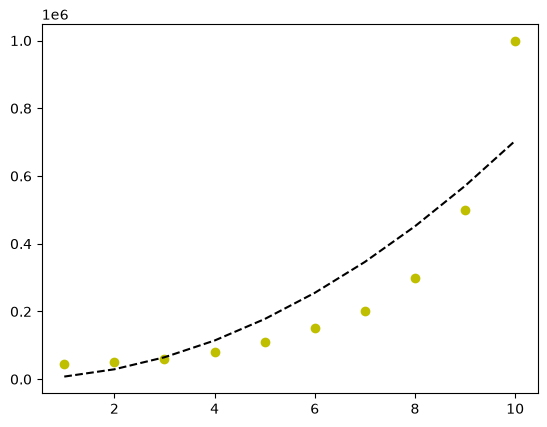

In [68]:
X_plot = df.Level
y_func = poly_model.theta[2] * X * X + poly_model.theta[1] * X + poly_model.theta[0]
plt.plot(X_plot, y, 'yo', X, y_func, '--k')
plt.show()

In [69]:
# Polymial Regression with degree = 3
X_poly = create_polynomial_features(X, degree = 3)
X_poly

array([[   1.,    1.,    1.,    1.],
       [   1.,    2.,    4.,    8.],
       [   1.,    3.,    9.,   27.],
       [   1.,    4.,   16.,   64.],
       [   1.,    5.,   25.,  125.],
       [   1.,    6.,   36.,  216.],
       [   1.,    7.,   49.,  343.],
       [   1.,    8.,   64.,  512.],
       [   1.,    9.,   81.,  729.],
       [   1.,   10.,  100., 1000.]])

In [70]:
poly_model = LinearRegression(X_poly, y, learning_rate = 0.000001, num_epochs = 100)
poly_model.fit()

Epoch: 0 - Loss : 142542480462.2734
Epoch: 1 - Loss : 55699455355.73309
Epoch: 2 - Loss : 24506298969.09066
Epoch: 3 - Loss : 13301830917.635067
Epoch: 4 - Loss : 9277032355.011509
Epoch: 5 - Loss : 7831075096.7102375
Epoch: 6 - Loss : 7311403218.073805
Epoch: 7 - Loss : 7124440742.196218
Epoch: 8 - Loss : 7056983120.214539
Epoch: 9 - Loss : 7032450130.835681
Epoch: 10 - Loss : 7023335183.191299
Epoch: 11 - Loss : 7019758277.854729
Epoch: 12 - Loss : 7018170651.200719
Epoch: 13 - Loss : 7017297634.791748
Epoch: 14 - Loss : 7016681384.754254
Epoch: 15 - Loss : 7016157449.66892
Epoch: 16 - Loss : 7015666760.760397
Epoch: 17 - Loss : 7015188101.289042
Epoch: 18 - Loss : 7014713850.45997
Epoch: 19 - Loss : 7014241270.959749
Epoch: 20 - Loss : 7013769379.556168
Epoch: 21 - Loss : 7013297823.0595
Epoch: 22 - Loss : 7012826474.582883
Epoch: 23 - Loss : 7012355288.524408
Epoch: 24 - Loss : 7011884248.47865
Epoch: 25 - Loss : 7011413348.52717
Epoch: 26 - Loss : 7010942586.518321
Epoch: 27 - Los

{'loss': np.float64(9114776156.746668),
 'weight': array([ 2.96957768e-01, -2.74433907e+00,  2.68717060e+01,  8.25812443e+02])}

In [71]:
y_pred = poly_model.predict(X_poly)
r2score(y_pred, y)

np.float64(0.9135099388319886)

In [72]:
poly_model.theta

array([ 2.96957768e-01, -2.74433907e+00,  2.68717060e+01,  8.25812443e+02])

0       850.236768
1      6708.794647
2     22530.845252
3     53271.263242
4    103884.923272
5    179326.700001
6    284551.468086
7    424514.102184
8    604169.476951
9    828472.467047
Name: Level, dtype: float64


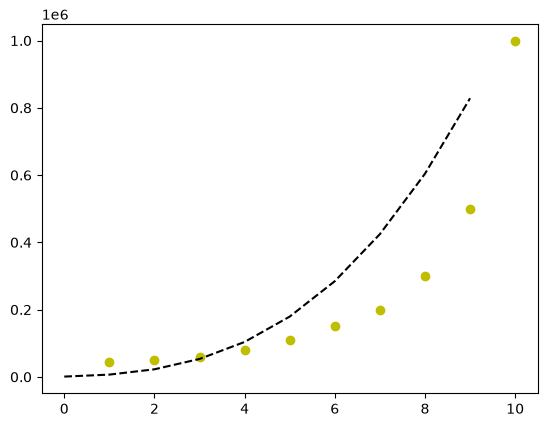

In [73]:
X_plot = df.Level
y_func = poly_model.theta[3] * X * X * X + poly_model.theta[2] * X * X + poly_model.theta[1] * X + poly_model.theta[0]

print(y_func)
plt.plot(X_plot, y, 'yo', y_func, '--k')
plt.show()

In [74]:
from scipy import optimize

def func(x, a, b):
    y = a * x + b
    y = a * np.exp(b * X)
    return y

In [75]:
X

0     1
1     2
2     3
3     4
4     5
5     6
6     7
7     8
8     9
9    10
Name: Level, dtype: int64

In [76]:
y

0      45000
1      50000
2      60000
3      80000
4     110000
5     150000
6     200000
7     300000
8     500000
9    1000000
Name: Salary, dtype: int64

In [77]:
optimize.curve_fit(func, xdata = X, ydata = y)

(array([4.58939073e+03, 5.34689948e-01]),
 array([[ 3.29356997e+06, -7.50606576e+01],
        [-7.50606576e+01,  1.72574617e-03]]))

In [78]:
alpha, beta = optimize.curve_fit(func, xdata = X, ydata = y)[0]
print(f'alpha = {alpha}, beta = {beta}')

alpha = 4589.390728026566, beta = 0.5346899475514073


In [79]:
y_pred = func(X, alpha, beta)
r2score(y_pred, y)

np.float64(0.9808034598161849)

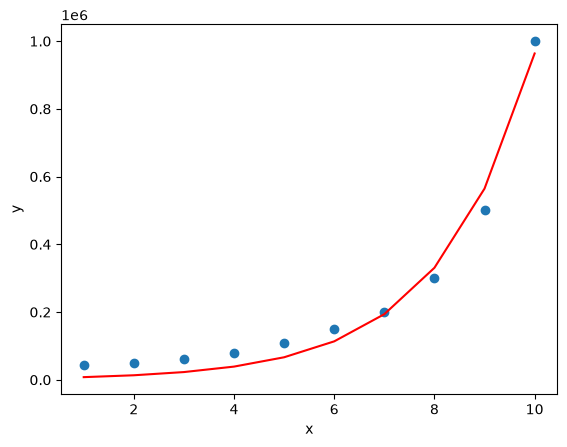

In [81]:
plt.scatter(X, y)
plt.plot(X, alpha * np.exp(X * beta), 'r')
plt.xlabel('x')
plt.ylabel('y')
plt.show()